<a href="https://colab.research.google.com/github/rperezen/intro-to-ML/blob/main/hw_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 500, Loss 10.708596
Epoch 1000, Loss 8.642083
Epoch 1500, Loss 7.171005
Epoch 2000, Loss 6.123478
Epoch 2500, Loss 5.377227
Epoch 3000, Loss 4.845286
Epoch 3500, Loss 4.465788
Epoch 4000, Loss 4.194724
Epoch 4500, Loss 4.000802
Epoch 5000, Loss 3.861744


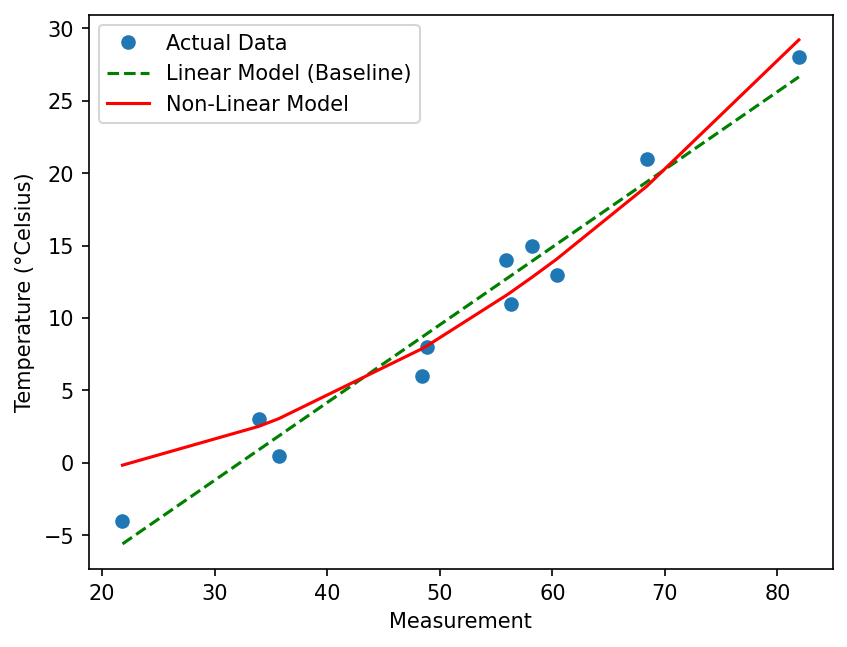

In [2]:
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

# --- Data Setup ---
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]

t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

t_un = 0.1 * t_u

# --- Model & Loss Definitions ---
def model(t_u, w2, w1, b):
    return w2 * t_u ** 2 + w1 * t_u + b

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()

def training_loop(n_epochs, optimizer, params, t_u, t_c):
    for epoch in range(1, n_epochs + 1):
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, float(loss.detach())))

    return params

# --- Single Training Session (Slide Format) ---

params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
learning_rate = 0.0001 # Reduced learning rate to prevent exploding gradients
optimizer = optim.SGD([params], lr=learning_rate)

training_loop(
    n_epochs = 5000,
    optimizer = optimizer,
    params = params,
    t_u = t_un,
    t_c = t_c)

# --- 1.c Visualization and Comparison ---

# The linear baseline results from the lecture (using normalized t_un)
linear_w = 5.3671
linear_b = -17.3012
t_p_linear = linear_w * t_un + linear_b

t_p_nonlinear = model(t_un, *params)

# Sort values for smooth line plotting
t_u_sorted, indices = torch.sort(t_u)
t_p_linear_sorted = t_p_linear[indices]
t_p_nonlinear_sorted = t_p_nonlinear[indices]

# Plotting
fig = plt.figure(dpi=150)
plt.xlabel("Measurement")
plt.ylabel("Temperature (°Celsius)")

plt.plot(t_u.numpy(), t_c.numpy(), 'o', label='Actual Data')
plt.plot(t_u_sorted.numpy(), t_p_linear_sorted.detach().numpy(), 'g--', label='Linear Model (Baseline)')
plt.plot(t_u_sorted.numpy(), t_p_nonlinear_sorted.detach().numpy(), 'r-', label='Non-Linear Model')

plt.legend()
plt.show()